In [30]:
import xarray as xr
import numpy as np
import dask
import cartopy
import cartopy.crs as ccrs
import cartopy.feature as cfeature
import matplotlib.pyplot as plt

In [48]:
path = '/jetfs/scratch/psplechtna/thesisdata/sfcfluxes/clim_fluxes.zarr/'
path_single = '/jetfs/scratch/psplechtna/thesisdata/sfcfluxes/fluxes_per_sec_2024.nc'

In [49]:
clim_flux = xr.open_mfdataset(path)
flux_20 = xr.open_dataset(path_single)

In [53]:
lh_clim = clim_flux['slhf'].sel(mdh=81212)
lh_20 = flux_20['slhf'].sel(valid_time='2024-08-12T12:00:00.000000000')

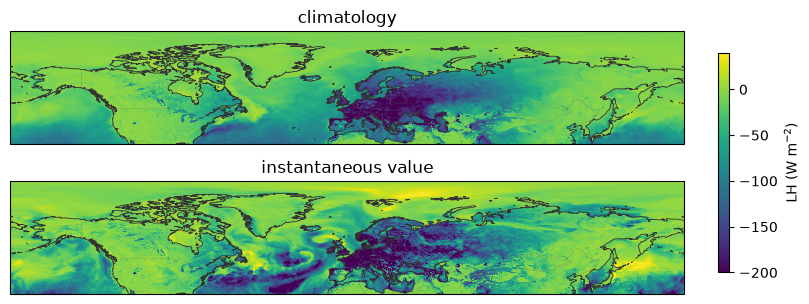

In [54]:
lonmin, lonmax = -179, 180
latmin, latmax =   30,  90

map_proj  = ccrs.PlateCarree()
data_proj = ccrs.PlateCarree()

fig, ax = plt.subplots(2, 1, figsize=(8,3),
                        subplot_kw={'projection': map_proj},
                        constrained_layout=True)
kw = dict(transform=data_proj, shading='auto', cmap='viridis', vmin=-200, vmax=40)
m0 = ax[0].pcolormesh(lh_clim.longitude, lh_clim.latitude, lh_clim, **kw)
m1 = ax[1].pcolormesh(lh_20.longitude,  lh_20.latitude,  lh_20,  **kw)

ax[0].set_title('climatology')
ax[1].set_title('instantaneous value')

fig.colorbar(m1, ax=ax, orientation='vertical', shrink=0.8, label='LH (W m$^{-2}$)')

for axs in ax:
    axs.set_extent([lonmin, lonmax, latmin, latmax], crs=data_proj)
    axs.add_feature(cfeature.COASTLINE.with_scale('50m'),
                       linewidth=0.6, edgecolor='0.2', zorder=5)
    axs.add_feature(cfeature.BORDERS.with_scale('50m'),
                       linewidth=0.4, linestyle=':', edgecolor='0.4', zorder=5)